In [1]:
import logging
import random
import re
import numpy as np
import pandas as pd
import seaborn as sns
import sympy as sp
import matplotlib.pyplot as plt
from sympy import simplify
from main import run_ga
import threading

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(message)s"
)

differential = False

def regression_metrics(y_true: np.ndarray, y_pred: np.ndarray):
    residuals = y_true - y_pred
    ss_res = float(np.sum(residuals ** 2))
    ss_tot = float(np.sum((y_true - np.mean(y_true)) ** 2))
    r2 = 1 - ss_res / ss_tot if ss_tot else float("nan")
    rmse = float(np.sqrt(np.mean(residuals ** 2)))
    return r2, rmse

def simplify_with_timeout(expr, timeout_seconds=5):
    """
    Attempt to simplify with a timeout using threading.
    Returns simplified expression or original if timeout occurs.
    """
    result = [None]
    exception = [None]
    
    def target():
        try:
            result[0] = simplify(expr)
        except Exception as e:
            exception[0] = e
    
    thread = threading.Thread(target=target, daemon=True)
    thread.start()
    thread.join(timeout=timeout_seconds)
    
    if thread.is_alive():
        print(f"Warning: Simplification timed out after {timeout_seconds}s, using unsimplified expression")
        return expr
    
    if exception[0]:
        raise exception[0]
    
    return result[0]


Using device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
CUDA Version: 12.9


In [2]:
df = pd.read_csv("monsoon.csv")

df_long = df.melt(
    id_vars=["PARAMETER", "YEAR"],
    var_name="MONTH",
    value_name="VALUE"
)

df_pivot = df_long.pivot_table(
    index=["YEAR", "MONTH"],
    columns="PARAMETER",
    values="VALUE"
).reset_index()

month_map = {"JAN": 1, "FEB": 2, "MAR": 3, "APR": 4, "MAY": 5,
             "JUN": 6, "JUL": 7, "AUG": 8, "SEP": 9,
             "OCT": 10, "NOV": 11, "DEC": 12}

df_pivot["MONTH_NUM"] = df_pivot["MONTH"].map(month_map)

df_pivot["DATE"] = pd.to_datetime(
    df_pivot["YEAR"].astype(str) + "-" + df_pivot["MONTH_NUM"].astype(str)
)
df_pivot.set_index("DATE", inplace=True)

df_final = df_pivot.drop(columns=["YEAR", "MONTH", "MONTH_NUM"])

def sanitize(name: str) -> str:
    s = name.strip()
    s = re.sub(r"\W+", "_", s)
    if s and s[0].isdigit():
        s = f"v_{s}"
    return s

col_map = {c: sanitize(c) for c in df_final.columns}
df_final.rename(columns=col_map, inplace=True)

df_final = (
    df_final.apply(pd.to_numeric, errors="coerce")
    .replace([pd.NA, float("inf"), -float("inf")], pd.NA)
    .dropna()
)
if differential:
    for column in df_final.columns:
        df_final[f"d{column}"] = np.gradient(df_final[column].to_numpy(dtype=float))
%matplotlib inline

Correlation matrix: PARAMETER          Precipitation  Soil_Moisture  Specific_Humidity  \
PARAMETER                                                            
Precipitation           1.000000       0.482160           0.585487   
Soil_Moisture           0.482160       1.000000           0.788807   
Specific_Humidity       0.585487       0.788807           1.000000   
Temperature            -0.421531      -0.789661          -0.709625   

PARAMETER          Temperature  
PARAMETER                       
Precipitation        -0.421531  
Soil_Moisture        -0.789661  
Specific_Humidity    -0.709625  
Temperature           1.000000  


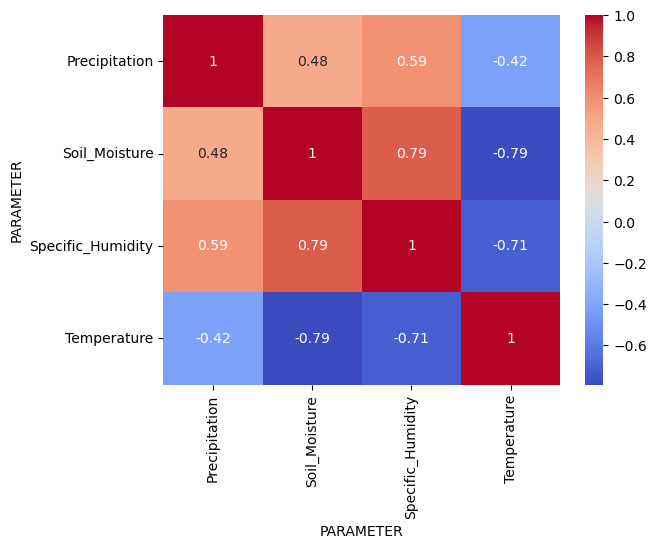

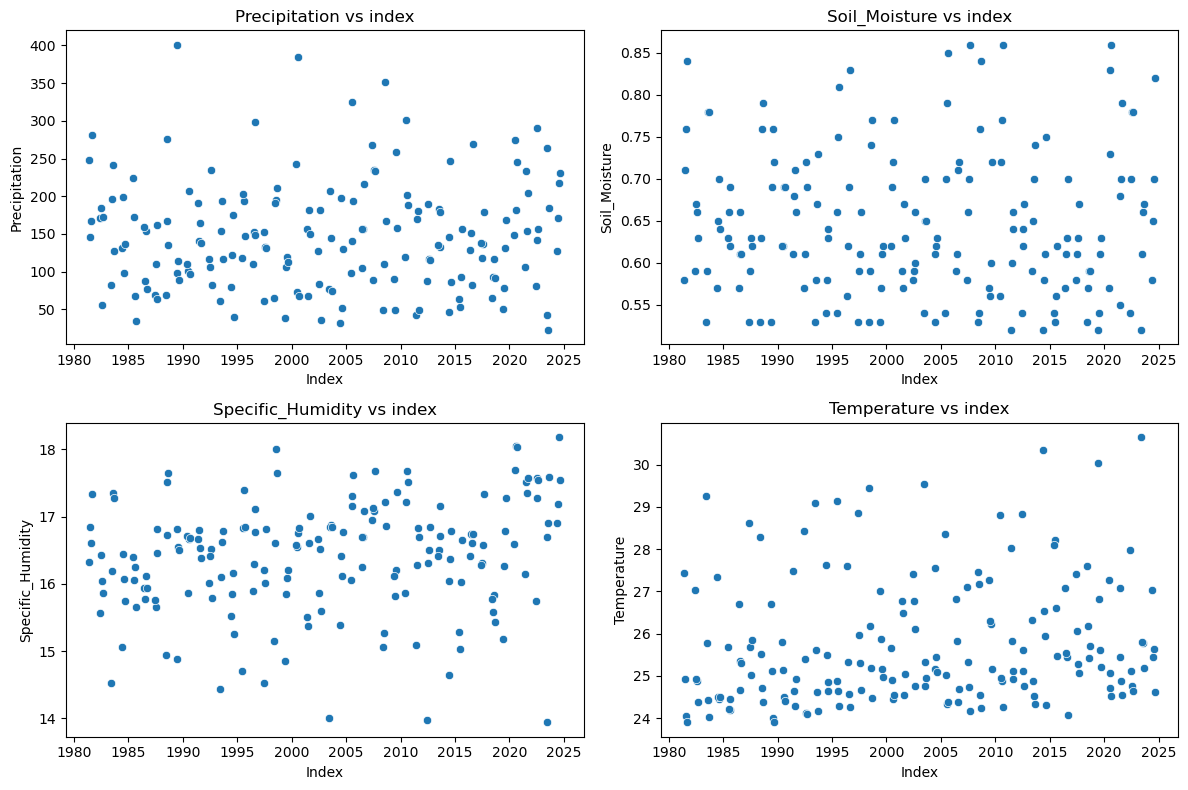

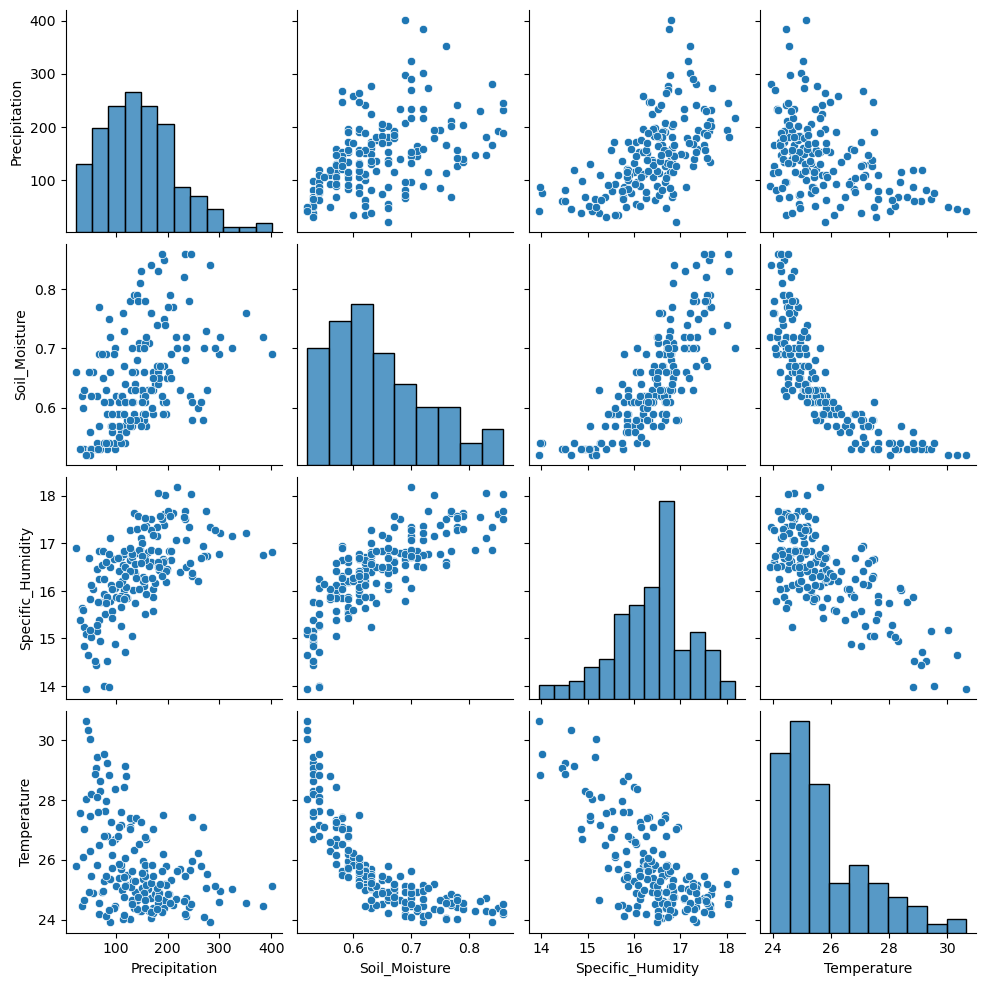

In [3]:
target = "So"
if differential:
    df_final.pop(f"d{target}")
print("Correlation matrix:", df_final.corr())
sns.heatmap(data=df_final.corr(), annot=True, cmap="coolwarm")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, col in zip(axes, df_final.columns):
    sns.scatterplot(x=df_final.index, y=df_final[col], ax=ax)
    ax.set_title(f"{col} vs index")
    ax.set_xlabel("Index")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

sns.pairplot(df_final)
plt.savefig("pairplot.pdf", bbox_inches='tight')
plt.show()


In [4]:
target = "Soil_Moisture"
SEED = 42
feature_cols = [c for c in df_final.columns if c != target]
print(df_final.head())

X = df_final[feature_cols].to_numpy(dtype=float)
y = df_final[target].to_numpy(dtype=float)

unary_funcs = {
        'sin': (np.sin, sp.sin),
        'cos': (np.cos, sp.cos),
        'tan': (np.tan, sp.tan),
        'exp': (np.exp, sp.exp),
        'sqrt': (np.sqrt, sp.sqrt)
    }

PARAMETER   Precipitation  Soil_Moisture  Specific_Humidity  Temperature
DATE                                                                    
1981-08-01         167.08           0.76              16.60        24.05
1981-07-01         145.41           0.71              16.84        24.93
1981-06-01         247.83           0.58              16.32        27.44
1981-09-01         281.74           0.84              17.34        23.92
1982-08-01          55.79           0.66              16.04        24.88


Running genetic algorithm for 'Soil_Moisture' against ['Precipitation', 'Specific_Humidity', 'Temperature']
Using learned subtree crossover with MLP (10 layers, 128 hidden, gelu activation, 0.1 dropout, A2C (with critic))


/home/sandy/test/main.py:913: RuntimeWarning: overflow encountered in square
  mse = float(np.mean((y - y_pred)**2))
/home/sandy/test/main.py:162: RuntimeWarning: invalid value encountered in sqrt
  return f(self.child.evaluate(inputs))
/home/sandy/test/main.py:162: RuntimeWarning: overflow encountered in exp
  return f(self.child.evaluate(inputs))
/home/sandy/test/main.py:162: RuntimeWarning: invalid value encountered in tan
  return f(self.child.evaluate(inputs))
/home/sandy/test/main.py:189: RuntimeWarning: overflow encountered in multiply
  return f(self.left.evaluate(inputs), self.right.evaluate(inputs))
/home/sandy/test/main.py:162: RuntimeWarning: invalid value encountered in sin
  return f(self.child.evaluate(inputs))
/home/sandy/test/main.py:162: RuntimeWarning: invalid value encountered in cos
  return f(self.child.evaluate(inputs))


Gen   1 best MSE+penalty: 1.0169 R²: -1.317744 expr: sin(sin(((-0.5468 / Precipitation) + (Precipitation / Precipitation))))


/home/sandy/test/main.py:189: RuntimeWarning: invalid value encountered in add
  return f(self.left.evaluate(inputs), self.right.evaluate(inputs))


Gen  10 best MSE+penalty: 0.00399195 R²: 0.471592 expr: cos(cos((((tan(Precipitation) / Precipitation) + sqrt(Temperature)) + (exp(-0.4373) + (Specific_Humidity / Precipitation)))))


/home/sandy/test/main.py:189: RuntimeWarning: invalid value encountered in multiply
  return f(self.left.evaluate(inputs), self.right.evaluate(inputs))
/home/sandy/test/main.py:189: RuntimeWarning: invalid value encountered in subtract
  return f(self.left.evaluate(inputs), self.right.evaluate(inputs))


... (3 outputs left out)

/home/sandy/.local/lib/python3.13/site-packages/numpy/_core/_methods.py:135: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


Gen 120 best MSE+penalty: 0.000911751 R²: 0.915643 expr: exp((((exp(sin((sin((exp(0.541) + Specific_Humidity)) - Temperature))) + Specific_Humidity) - Temperature) / (Precipitation / (Precipitation / (exp(sin(Specific_Humidity)) + ((exp(sin(Specific_Humidity)) + Specific_Humidity) + 0.541))))))
Gen 130 best MSE+penalty: 0.000876194 R²: 0.924682 expr: exp((((exp(sin((sin((exp(sin((0.1091 - Temperature))) + Specific_Humidity)) - Temperature))) + Specific_Humidity) - Temperature) / (Precipitation / (Precipitation / (exp(sin(Specific_Humidity)) + ((exp(sin(Specific_Humidity)) + Specific_Humidity) + 0.541))))))


/home/sandy/test/main.py:26: RuntimeWarning: overflow encountered in divide
  return a / (b + 1e-6)


Gen 140 best MSE+penalty: 0.000876194 R²: 0.924682 expr: exp((((exp(sin((sin((exp(sin((0.1091 - Temperature))) + Specific_Humidity)) - Temperature))) + Specific_Humidity) - Temperature) / (Precipitation / (Precipitation / (exp(sin(Specific_Humidity)) + ((exp(sin(Specific_Humidity)) + Specific_Humidity) + 0.541))))))
Gen 150 best MSE+penalty: 0.00086509 R²: 0.927593 expr: exp((((exp(sin((sin((exp(sin(sin((0.1091 - Temperature)))) + Specific_Humidity)) - Temperature))) + Specific_Humidity) - Temperature) / (Precipitation / (Precipitation / (exp(sin(Specific_Humidity)) + ((exp(sin(Specific_Humidity)) + Specific_Humidity) + 0.541))))))
Gen 160 best MSE+penalty: 0.00086509 R²: 0.927593 expr: exp((((exp(sin((sin((exp(sin(sin((0.1091 - Temperature)))) + Specific_Humidity)) - Temperature))) + Specific_Humidity) - Temperature) / (Precipitation / (Precipitation / (exp(sin(Specific_Humidity)) + ((exp(sin(Specific_Humidity)) + Specific_Humidity) + 0.541))))))
Gen 170 best MSE+penalty: 0.00086509 R

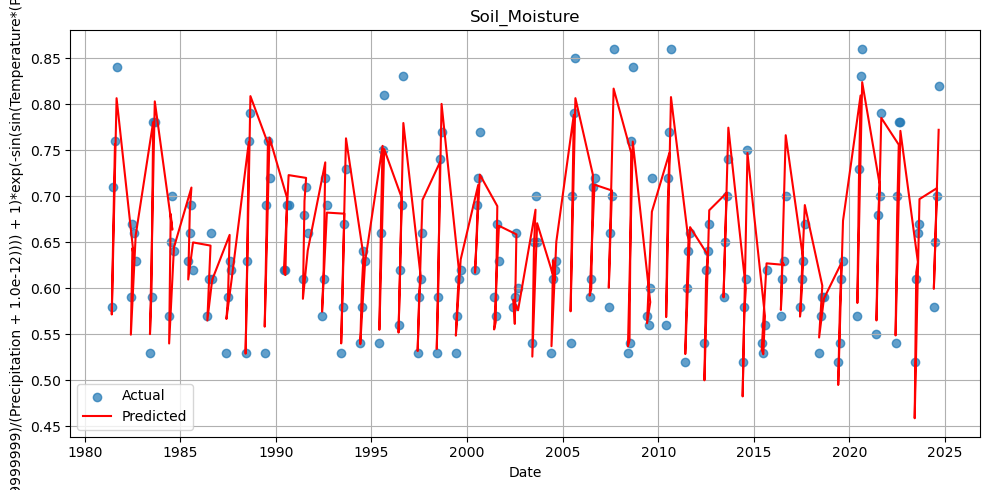

In [5]:
print(f"Running genetic algorithm for '{target}' against {feature_cols}")
best, best_score = run_ga(
    X,
    y,
    pop_size=1500,
    gens=300,
    max_init_depth=4,
    max_depth=10,
    crossover_rate=0.85,
    mutation_rate=0.2,
    tournament_k=5,
    elitism=15,
    var_names=feature_cols,
    unary_funcs=unary_funcs,
    use_learned_crossover=True,
    selector_lr=0.0005,
    use_transformer=False,
    transformer_heads=8,
    transformer_layers=4,
    mlp_layers=10,
    mlp_hidden_dim=128,
    mlp_activation="gelu",
    mlp_dropout=0.1,
    stopping_metric="r2",
    stopping_threshold=None,
    # NEW: Additional customization options
    complexity_coef=1e-5,
    inclusion_coef=0.5,
    prob_const=0.35,
    const_range=(-3, 3),
    point_mutation_prob=0.1,
    selector_update_freq=3,
    temperature=0.7,
    critic_weight=0.6,
    entropy_weight=0.02,
    verbose=True,
    print_freq=10,
    seed=SEED,
)

if best is None:
    raise RuntimeError("Genetic algorithm did not return a valid expression.")

sym_expr = simplify_with_timeout(best.to_sympy(), timeout_seconds=30)
feature_values = {name: df_final[name].to_numpy(dtype=float) for name in feature_cols}
y_pred = best.evaluate(feature_values)
r2, rmse = regression_metrics(y, y_pred)

print(f"Best score (MSE + penalty): {best_score:.6f}")
print(f"Sympy expression: {sym_expr}")
print(f"R2: {r2:.4f}, RMSE: {rmse:.4f}")

plt.figure(figsize=(10, 5))
plt.scatter(df_final.index, y, label="Actual", alpha=0.7)
plt.plot(df_final.index, y_pred, label="Predicted", color="red")
plt.title(target)
plt.xlabel("Date")
plt.ylabel(str(sym_expr))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("predict.pdf", bbox_inches='tight')
plt.show()

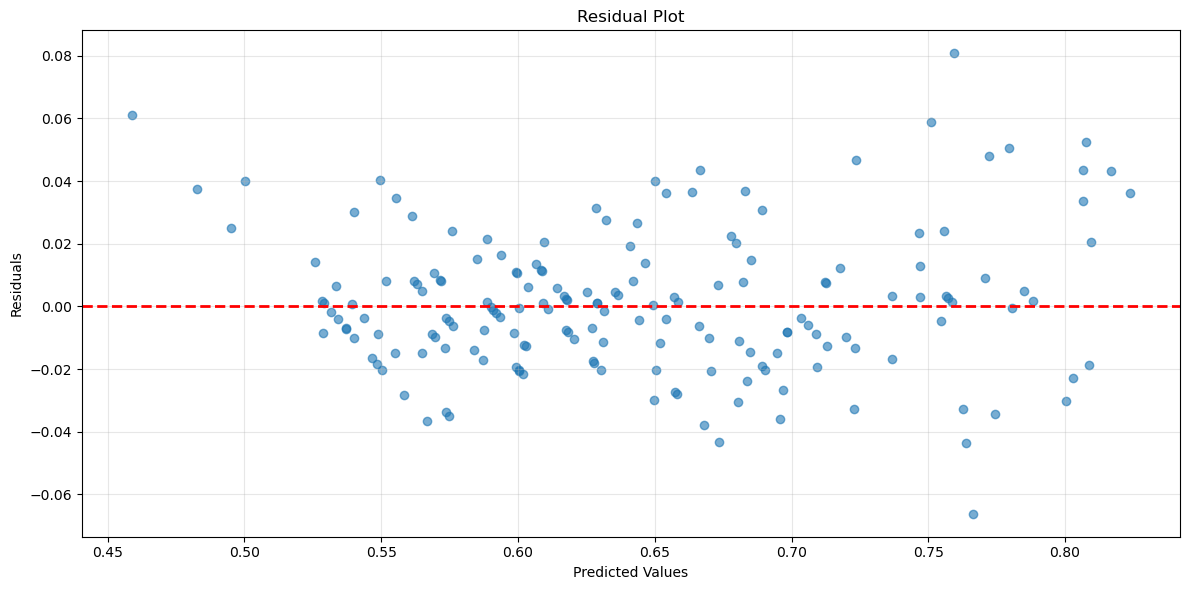

In [6]:
residuals = y - y_pred
plt.figure(figsize=(12, 6))
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(y=0, color='r', linestyle='--', linewidth=2)
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
print(f"In LaTeX format: {sp.latex(sym_expr)}")
replacements, reduced_exprs = sp.cse(sym_expr)
print("CSE replacements (LaTeX):")
for idx, (sym, expr) in enumerate(replacements, 1):
    print(f"$t_{{{idx}}}: {sp.latex(sym)} = {sp.latex(expr)}$")

print("CSE reduced expressions (LaTeX):")
for idx, expr in enumerate(reduced_exprs, 1):
    print(f"$e_{{{idx}}}: {sp.latex(expr)}$")

In LaTeX format: e^{\frac{Specific_{Humidity} - Temperature + e^{- \sin{\left(Temperature - \sin{\left(\left(Specific_{Humidity} e^{\sin{\left(\sin{\left(\frac{Temperature \left(Precipitation - 0.999999999999\right)}{Precipitation + 1.0 \cdot 10^{-12}} \right)} \right)}} + 1\right) e^{- \sin{\left(\sin{\left(\frac{Temperature \left(Precipitation - 0.999999999999\right)}{Precipitation + 1.0 \cdot 10^{-12}} \right)} \right)}} \right)} \right)}}}{Specific_{Humidity} + 2 e^{\sin{\left(Specific_{Humidity} \right)}} + 0.541006861443424}}
CSE replacements (LaTeX):
$t_{1}: x_{0} = \sin{\left(\sin{\left(\frac{Temperature \left(Precipitation - 0.999999999999\right)}{Precipitation + 1.0 \cdot 10^{-12}} \right)} \right)}$
CSE reduced expressions (LaTeX):
$e_{1}: e^{\frac{Specific_{Humidity} - Temperature + e^{- \sin{\left(Temperature - \sin{\left(\left(Specific_{Humidity} e^{x_{0}} + 1\right) e^{- x_{0}} \right)} \right)}}}{Specific_{Humidity} + 2 e^{\sin{\left(Specific_{Humidity} \right)}} + 0.54

In [8]:
sym_expr


exp((Specific_Humidity - Temperature + exp(-sin(Temperature - sin((Specific_Humidity*exp(sin(sin(Temperature*(Precipitation - 0.999999999999)/(Precipitation + 1.0e-12)))) + 1)*exp(-sin(sin(Temperature*(Precipitation - 0.999999999999)/(Precipitation + 1.0e-12))))))))/(Specific_Humidity + 2*exp(sin(Specific_Humidity)) + 0.541006861443424))

In [9]:
best.to_string()


'exp((((exp(sin((sin((exp(sin(sin(((Temperature / Precipitation) - Temperature)))) + Specific_Humidity)) - Temperature))) + Specific_Humidity) - Temperature) / (exp(sin(Specific_Humidity)) + ((exp(sin(Specific_Humidity)) + Specific_Humidity) + 0.541))))'

Using random subtree crossover


/home/sandy/test/main.py:919: RuntimeWarning: overflow encountered in square
  mse = float(np.mean((y - y_pred)**2))
/home/sandy/test/main.py:162: RuntimeWarning: invalid value encountered in sqrt
  return f(self.child.evaluate(inputs))
/home/sandy/test/main.py:162: RuntimeWarning: overflow encountered in exp
  return f(self.child.evaluate(inputs))
/home/sandy/test/main.py:162: RuntimeWarning: invalid value encountered in tan
  return f(self.child.evaluate(inputs))
/home/sandy/test/main.py:189: RuntimeWarning: overflow encountered in multiply
  return f(self.left.evaluate(inputs), self.right.evaluate(inputs))
/home/sandy/test/main.py:162: RuntimeWarning: invalid value encountered in sin
  return f(self.child.evaluate(inputs))
/home/sandy/test/main.py:162: RuntimeWarning: invalid value encountered in cos
  return f(self.child.evaluate(inputs))


Gen   1 best MSE+penalty: 1.0169 R²: -1.317744 expr: sin(sin(((-0.5468 / Precipitation) + (Precipitation / Precipitation))))


/home/sandy/test/main.py:189: RuntimeWarning: invalid value encountered in subtract
  return f(self.left.evaluate(inputs), self.right.evaluate(inputs))
/home/sandy/test/main.py:189: RuntimeWarning: invalid value encountered in multiply
  return f(self.left.evaluate(inputs), self.right.evaluate(inputs))
/home/sandy/test/main.py:26: RuntimeWarning: invalid value encountered in divide
  return a / (b + 1e-6)


Gen  10 best MSE+penalty: 0.00468715 R²: 0.455707 expr: cos(cos((exp(-0.4411) * sin((sin((Temperature - cos(cos(sin((tan(exp((sqrt(0.0002219) - cos((((Temperature - (-2.94 + -0.9345)) / Precipitation) - sqrt(Specific_Humidity)))))) - (Precipitation + -0.9345))))))) - cos(cos(sin((tan(sin((sqrt(0.0002219) - cos((((tan(sin(Precipitation)) - (((1.74 / -2.824) * (tan(-2.319) + 1.821)) - (Precipitation + (cos((Precipitation / 1.146)) * -0.07791)))) / (-1.198 / Precipitation)) - sqrt(Specific_Humidity)))))) - (Precipitation + -0.9345))))))))))
Gen  20 best MSE+penalty: 0.00314074 R²: 0.649644 expr: cos(cos((tan(((Specific_Humidity - 1.566) / (cos(sin(2.801)) - Temperature))) * sin((sin((Temperature - cos(cos(sin((tan(sin(((exp(-0.9595) * sin((sin((Temperature - sqrt(Specific_Humidity))) - cos(cos(sin((-1.111 + Precipitation))))))) - cos((((Temperature - (-2.94 + -0.9345)) / cos(1.438)) - sqrt(Specific_Humidity)))))) - (Precipitation + -0.9345))))))) - cos(cos(sin(Temperature))))))))
Gen  30 

/home/sandy/test/main.py:189: RuntimeWarning: invalid value encountered in add
  return f(self.left.evaluate(inputs), self.right.evaluate(inputs))


Gen 120 best MSE+penalty: 0.00102368 R²: 0.902966 expr: cos(cos((tan(((Specific_Humidity - 1.566) / (0.9244 - ((Precipitation / Precipitation) - sqrt(Specific_Humidity))))) * sin((sin((Temperature - cos((sin((Temperature - sqrt(0.9244))) - tan(0.5079))))) - cos(0.9244))))))
Gen 130 best MSE+penalty: 0.00101309 R²: 0.903047 expr: cos(cos((tan(((Specific_Humidity - 1.566) / (0.9244 - ((Precipitation / Precipitation) - sqrt(Specific_Humidity))))) * sin((sin((Temperature - cos((sin((Temperature - 0.9244)) - tan(0.5079))))) - cos(0.9244))))))


/home/sandy/test/main.py:26: RuntimeWarning: overflow encountered in divide
  return a / (b + 1e-6)


Gen 140 best MSE+penalty: 0.00101309 R²: 0.903047 expr: cos(cos((tan(((Specific_Humidity - 1.566) / (0.9244 - ((Precipitation / Precipitation) - sqrt(Specific_Humidity))))) * sin((sin((Temperature - cos((sin((Temperature - 0.9244)) - tan(0.5079))))) - cos(0.9244))))))
Gen 150 best MSE+penalty: 0.00101309 R²: 0.903047 expr: cos(cos((tan(((Specific_Humidity - 1.566) / (0.9244 - ((Precipitation / Precipitation) - sqrt(Specific_Humidity))))) * sin((sin((Temperature - cos((sin((Temperature - 0.9244)) - tan(0.5079))))) - cos(0.9244))))))
Gen 160 best MSE+penalty: 0.00101309 R²: 0.903047 expr: cos(cos((tan(((Specific_Humidity - 1.566) / (0.9244 - ((Precipitation / Precipitation) - sqrt(Specific_Humidity))))) * sin((sin((Temperature - cos((sin((Temperature - 0.9244)) - tan(0.5079))))) - cos(0.9244))))))
Gen 170 best MSE+penalty: 0.00101309 R²: 0.903047 expr: cos(cos((tan(((Specific_Humidity - 1.566) / (0.9244 - ((Precipitation / Precipitation) - sqrt(Specific_Humidity))))) * sin((sin((Temperat

/home/sandy/.local/lib/python3.13/site-packages/numpy/_core/_methods.py:135: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


Gen 120 best MSE+penalty: 0.000911751 R²: 0.915643 expr: exp((((exp(sin((sin((exp(0.541) + Specific_Humidity)) - Temperature))) + Specific_Humidity) - Temperature) / (Precipitation / (Precipitation / (exp(sin(Specific_Humidity)) + ((exp(sin(Specific_Humidity)) + Specific_Humidity) + 0.541))))))
Gen 130 best MSE+penalty: 0.000876194 R²: 0.924682 expr: exp((((exp(sin((sin((exp(sin((0.1091 - Temperature))) + Specific_Humidity)) - Temperature))) + Specific_Humidity) - Temperature) / (Precipitation / (Precipitation / (exp(sin(Specific_Humidity)) + ((exp(sin(Specific_Humidity)) + Specific_Humidity) + 0.541))))))
Gen 140 best MSE+penalty: 0.000876194 R²: 0.924682 expr: exp((((exp(sin((sin((exp(sin((0.1091 - Temperature))) + Specific_Humidity)) - Temperature))) + Specific_Humidity) - Temperature) / (Precipitation / (Precipitation / (exp(sin(Specific_Humidity)) + ((exp(sin(Specific_Humidity)) + Specific_Humidity) + 0.541))))))
Gen 150 best MSE+penalty: 0.00086509 R²: 0.927593 expr: exp((((exp(s

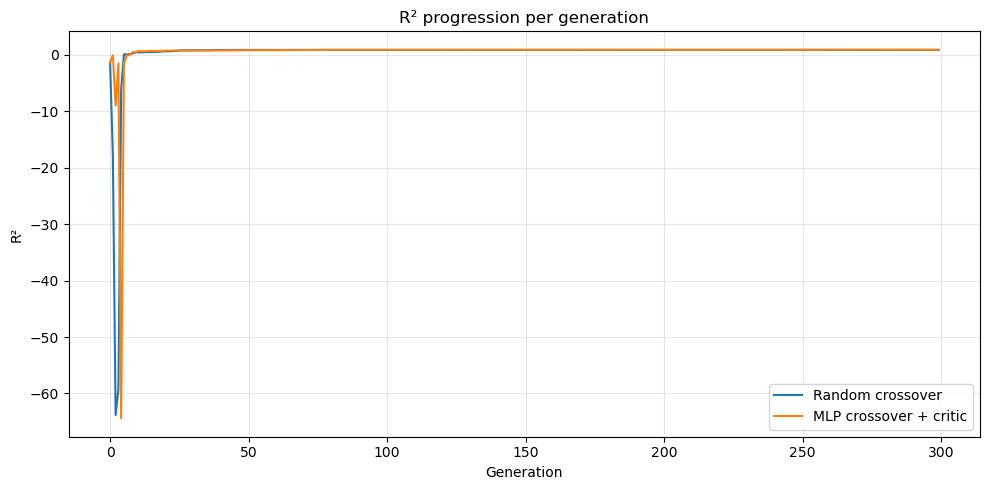

In [5]:
"""
Placeholder cell for future experimentation with hyper-parameter sweeps.

Example: Compare MLP vs Transformer with/without critic
"""

results = []
r2_history = {}

configs = [
    ("Random crossover", {"use_learned_crossover": False, "use_transformer": False, "use_critic": False}),
    ("MLP crossover + critic", {"use_learned_crossover": True, "use_transformer": False, "use_critic": True}),
]

for label, overrides in configs:
    history = []

    def on_generation(gen, r2):
        history.append((gen, r2))

    kwargs = dict(
        pop_size=1500,
        gens=300,
        max_init_depth=4,
        max_depth=10,
        crossover_rate=0.85,
        mutation_rate=0.2,
        tournament_k=5,
        elitism=15,
        var_names=feature_cols,
        unary_funcs=unary_funcs,
        selector_lr=0.0005,
        transformer_heads=8,
        transformer_layers=4,
        mlp_layers=10,
        mlp_hidden_dim=128,
        mlp_activation="gelu",
        mlp_dropout=0.1,
        stopping_metric="r2",
        stopping_threshold=None,
        complexity_coef=1e-5,
        inclusion_coef=0.5,
        prob_const=0.35,
        const_range=(-3, 3),
        point_mutation_prob=0.1,
        selector_update_freq=3,
        temperature=0.7,
        critic_weight=0.6,
        entropy_weight=0.02,
        verbose=True,
        print_freq=10,
        seed=SEED,
        metrics_callback=on_generation,
    )
    kwargs.update(overrides)

    best, score = run_ga(X, y, **kwargs)

    feature_values = {name: df_final[name].to_numpy(dtype=float) for name in feature_cols}
    y_pred = best.evaluate(feature_values)
    r2, rmse = regression_metrics(y, y_pred)

    r2_history[label] = history
    results.append({"config": label, "score": score, "r2": r2, "rmse": rmse, "expr": best.to_string()})

results_df = pd.DataFrame(results)
print(results_df[["config", "score", "r2", "rmse"]])

plt.figure(figsize=(10, 5))
for label, history in r2_history.items():
    if history:
        gens, r2_values = zip(*history)
        plt.plot(gens, r2_values, label=label)
plt.xlabel("Generation")
plt.ylabel("R²")
plt.title("R² progression per generation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()